In [87]:
#Step 2 – Import Required Librariesimport numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder, MinMaxScaler, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix



In [88]:
#Step 3 – Load Student Productivity Dataset
df = pd.read_csv("Student_Smart_Assistant_Dataset.csv")

In [89]:
#Step 4 – Display the Dataset
print(df)

       student_id  age  gender  study_hours_per_day  sleep_hours  \
0               1   23  Female                 4.35         3.63   
1               2   20    Male                 6.14         6.58   
2               3   29  Female                 4.98         3.26   
3               4   27  Female                 3.19         4.58   
4               5   24    Male                 7.67         6.21   
...           ...  ...     ...                  ...          ...   
19995       19996   26  Female                 4.81         7.83   
19996       19997   22   Other                 0.83         4.49   
19997       19998   25    Male                 9.36         4.33   
19998       19999   22  Female                 0.74         4.44   
19999       20000   19  Female                 3.64         6.35   

       phone_usage_hours  social_media_hours  youtube_hours  gaming_hours  \
0                   3.38                2.73           1.83          5.26   
1                   5.48     

In [90]:
#Step 5 – Display First Five Records
print(df.head())

   student_id  age  gender  study_hours_per_day  sleep_hours  \
0           1   23  Female                 4.35         3.63   
1           2   20    Male                 6.14         6.58   
2           3   29  Female                 4.98         3.26   
3           4   27  Female                 3.19         4.58   
4           5   24    Male                 7.67         6.21   

   phone_usage_hours  social_media_hours  youtube_hours  gaming_hours  \
0               3.38                2.73           1.83          5.26   
1               5.48                1.51           3.13          1.73   
2               4.83                3.63           0.18          4.71   
3              10.06                3.95           5.75          2.52   
4               3.02                1.59           5.46          5.65   

   breaks_per_day  coffee_intake_mg  exercise_minutes  assignments_completed  \
0               6               347               111                      2   
1              1

In [91]:
#Step 6 – Display Last Five Records
print(df.tail())

       student_id  age  gender  study_hours_per_day  sleep_hours  \
19995       19996   26  Female                 4.81         7.83   
19996       19997   22   Other                 0.83         4.49   
19997       19998   25    Male                 9.36         4.33   
19998       19999   22  Female                 0.74         4.44   
19999       20000   19  Female                 3.64         6.35   

       phone_usage_hours  social_media_hours  youtube_hours  gaming_hours  \
19995               6.86                6.93           2.77          5.68   
19996               6.76                3.79           2.95          1.38   
19997               2.94                6.98           0.35          1.42   
19998               3.15                5.99           3.11          5.01   
19999               8.68                0.11           5.19          1.28   

       breaks_per_day  coffee_intake_mg  exercise_minutes  \
19995               6               451                 0   
19996 

In [92]:
#Step 7 – Check Dataset Dimensions
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
print(df.shape)


Rows: 20000
Columns: 18
(20000, 18)


In [93]:
#Step 8 – Display Attribute Names
for column in df.columns:
   print(column)


student_id
age
gender
study_hours_per_day
sleep_hours
phone_usage_hours
social_media_hours
youtube_hours
gaming_hours
breaks_per_day
coffee_intake_mg
exercise_minutes
assignments_completed
attendance_percentage
stress_level
focus_score
final_grade
productivity_score


In [94]:
#Step 9 – Check Data Types
print(df.dtypes)
df.info()


student_id                 int64
age                        int64
gender                       str
study_hours_per_day      float64
sleep_hours              float64
phone_usage_hours        float64
social_media_hours       float64
youtube_hours            float64
gaming_hours             float64
breaks_per_day             int64
coffee_intake_mg           int64
exercise_minutes           int64
assignments_completed      int64
attendance_percentage    float64
stress_level               int64
focus_score                int64
final_grade              float64
productivity_score       float64
dtype: object
<class 'pandas.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 18 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   student_id             20000 non-null  int64  
 1   age                    20000 non-null  int64  
 2   gender                 20000 non-null  str    
 3   study_hours_per_day    20000 

In [95]:
#Step 10 – Generate Statistical Summary
print(df.describe())

         student_id          age  study_hours_per_day   sleep_hours  \
count  20000.000000  20000.00000         20000.000000  20000.000000   
mean   10000.500000     23.00745             5.254562      6.517799   
std     5773.647028      3.75489             2.742876      2.029784   
min        1.000000     17.00000             0.500000      3.000000   
25%     5000.750000     20.00000             2.900000      4.770000   
50%    10000.500000     23.00000             5.250000      6.510000   
75%    15000.250000     26.00000             7.640000      8.310000   
max    20000.000000     29.00000            10.000000     10.000000   

       phone_usage_hours  social_media_hours  youtube_hours  gaming_hours  \
count       20000.000000        20000.000000   20000.000000  20000.000000   
mean            6.250479            4.003655       2.990177      2.988339   
std             3.313082            2.305154       1.729815      1.732803   
min             0.500000            0.000000       0

In [96]:
#Step 11 – Check Missing Values
print(df.isnull().sum())

student_id               0
age                      0
gender                   0
study_hours_per_day      0
sleep_hours              0
phone_usage_hours        0
social_media_hours       0
youtube_hours            0
gaming_hours             0
breaks_per_day           0
coffee_intake_mg         0
exercise_minutes         0
assignments_completed    0
attendance_percentage    0
stress_level             0
focus_score              0
final_grade              0
productivity_score       0
dtype: int64


In [97]:
#Step 12 – Calculate Missing-Value Percentage
missing_percentage = (df.isnull().sum() / len(df)) * 100
print(missing_percentage)


student_id               0.0
age                      0.0
gender                   0.0
study_hours_per_day      0.0
sleep_hours              0.0
phone_usage_hours        0.0
social_media_hours       0.0
youtube_hours            0.0
gaming_hours             0.0
breaks_per_day           0.0
coffee_intake_mg         0.0
exercise_minutes         0.0
assignments_completed    0.0
attendance_percentage    0.0
stress_level             0.0
focus_score              0.0
final_grade              0.0
productivity_score       0.0
dtype: float64


In [98]:
#Step 13 – Handle Missing Values
import numpy as np
numeric_cols = df.select_dtypes(include=np.number).columns
categorical_cols = df.select_dtypes(include="str").columns

for col in numeric_cols:
    df[col] = df[col].fillna(df[col].median())

for col in categorical_cols:
    df[col] = df[col].fillna(df[col].mode()[0])


In [99]:
#Step 14 – Check Duplicate Records
print("Duplicate records:", df.duplicated().sum())

Duplicate records: 0


In [100]:
#Step 15 – Remove Duplicate Records
df = df.drop_duplicates()
print("Duplicate records after removal:", df.duplicated().sum())


Duplicate records after removal: 0


In [101]:
#Step 16 – Check Unique Gender Values
print(df["gender"].value_counts())
print(df["gender"].unique())

gender
Female    9640
Male      9582
Other      778
Name: count, dtype: int64
<StringArray>
['Female', 'Male', 'Other']
Length: 3, dtype: str


In [102]:
#Step 17 – Analyze Study Hours
print(df["study_hours_per_day"].describe())

count    20000.000000
mean         5.254562
std          2.742876
min          0.500000
25%          2.900000
50%          5.250000
75%          7.640000
max         10.000000
Name: study_hours_per_day, dtype: float64


In [103]:
#Step 18 – Analyze Sleep Hours
print(df["sleep_hours"].describe())

count    20000.000000
mean         6.517799
std          2.029784
min          3.000000
25%          4.770000
50%          6.510000
75%          8.310000
max         10.000000
Name: sleep_hours, dtype: float64


In [104]:
#Step 19 – Analyze Productivity Score
print(df["productivity_score"].describe())

count    20000.000000
mean        50.180419
std         16.086666
min          0.000000
25%         38.700000
50%         50.235000
75%         61.782500
max        100.000000
Name: productivity_score, dtype: float64


In [105]:
#Step 20 – Analyze Focus and Attendance
print(df["focus_score"].describe())
print(df["attendance_percentage"].describe())

count    20000.000000
mean        64.444350
std         20.176114
min         30.000000
25%         47.000000
50%         65.000000
75%         82.000000
max         99.000000
Name: focus_score, dtype: float64
count    20000.000000
mean        69.947435
std         17.397431
min         40.000000
25%         54.810000
50%         69.985000
75%         85.050000
max        100.000000
Name: attendance_percentage, dtype: float64


In [106]:
#Step 21 – Analyze Social Media Usage
print(df["social_media_hours"].describe())

count    20000.000000
mean         4.003655
std          2.305154
min          0.000000
25%          2.000000
50%          4.010000
75%          5.970000
max          8.000000
Name: social_media_hours, dtype: float64


In [107]:
#Step 22 – Analyze YouTube Usage
print(df["youtube_hours"].describe())

count    20000.000000
mean         2.990177
std          1.729815
min          0.000000
25%          1.487500
50%          2.980000
75%          4.480000
max          6.000000
Name: youtube_hours, dtype: float64


In [108]:
#Step 23 – Analyze Gaming Usage
print(df["gaming_hours"].describe())

count    20000.000000
mean         2.988339
std          1.732803
min          0.000000
25%          1.490000
50%          2.970000
75%          4.490000
max          6.000000
Name: gaming_hours, dtype: float64


In [109]:
#Step 24 – Analyze Exercise Duration
print(df["exercise_minutes"].describe())

count    20000.000000
mean        59.648050
std         34.611751
min          0.000000
25%         30.000000
50%         60.000000
75%         90.000000
max        119.000000
Name: exercise_minutes, dtype: float64


In [110]:
#Step 25 – Analyze Attendance Percentage
print(df["attendance_percentage"].describe())

count    20000.000000
mean        69.947435
std         17.397431
min         40.000000
25%         54.810000
50%         69.985000
75%         85.050000
max        100.000000
Name: attendance_percentage, dtype: float64


In [111]:
#Step 26 – Analyze Focus and Stress
print(df["focus_score"].describe())
print(df["stress_level"].describe())


count    20000.000000
mean        64.444350
std         20.176114
min         30.000000
25%         47.000000
50%         65.000000
75%         82.000000
max         99.000000
Name: focus_score, dtype: float64
count    20000.000000
mean         5.478750
std          2.866943
min          1.000000
25%          3.000000
50%          5.000000
75%          8.000000
max         10.000000
Name: stress_level, dtype: float64


In [112]:
#Step 27 – Analyze Final Grade
print(df["final_grade"].describe())

count    20000.000000
mean        70.266409
std         17.282277
min         40.000000
25%         55.460000
50%         70.315000
75%         85.340000
max         99.990000
Name: final_grade, dtype: float64


In [113]:
#Step 28 – Analyze Productivity Score
print(df["productivity_score"].describe())

count    20000.000000
mean        50.180419
std         16.086666
min          0.000000
25%         38.700000
50%         50.235000
75%         61.782500
max        100.000000
Name: productivity_score, dtype: float64


In [114]:
#Step 29 – Analyze Assignment Completion
print(df["assignments_completed"].describe())

count    20000.000000
mean         9.494100
std          5.801469
min          0.000000
25%          4.000000
50%          9.000000
75%         15.000000
max         19.000000
Name: assignments_completed, dtype: float64


In [115]:
#Step 30 – Analyze Coffee Intake
print(df["coffee_intake_mg"].describe())

count    20000.000000
mean       249.654550
std        143.711231
min          0.000000
25%        125.000000
50%        249.000000
75%        373.000000
max        499.000000
Name: coffee_intake_mg, dtype: float64


In [116]:
#Step 31 – Create Total Digital Distraction
df["digital_distraction_hours"] = (
    df["phone_usage_hours"]
    + df["social_media_hours"]
    + df["youtube_hours"]
    + df["gaming_hours"]
)
print(df[["student_id", "digital_distraction_hours"]].head())


   student_id  digital_distraction_hours
0           1                      13.20
1           2                      11.85
2           3                      13.35
3           4                      22.28
4           5                      15.72


In [117]:
#Step 32 – Create Study-to-Distraction Ratio
df["digital_distraction_hours"] = (
    df["phone_usage_hours"]
    + df["social_media_hours"]
    + df["youtube_hours"]
    + df["gaming_hours"]
)

df["study_distraction_ratio"] = (
    df["study_hours_per_day"] /
    (df["digital_distraction_hours"] + 0.01)
)

print(df[[
    "study_hours_per_day",
    "digital_distraction_hours",
    "study_distraction_ratio"
]].head())

   study_hours_per_day  digital_distraction_hours  study_distraction_ratio
0                 4.35                      13.20                 0.329296
1                 6.14                      11.85                 0.517707
2                 4.98                      13.35                 0.372754
3                 3.19                      22.28                 0.143114
4                 7.67                      15.72                 0.487603


In [118]:
#Step 33 – Create Productivity Category
df["productivity_category"] = pd.cut(
    df["productivity_score"],
    bins=[-np.inf, 40, 70, np.inf],
    labels=["Low", "Medium", "High"]
)
print(df["productivity_category"].value_counts())

productivity_category
Medium    12139
Low        5540
High       2321
Name: count, dtype: int64


In [119]:
#Step 34 – Create Distraction Category
df["distraction_level"] = pd.cut(
    df["digital_distraction_hours"],
    bins=[-np.inf, 6, 12, np.inf],
    labels=["Low", "Medium", "High"]
)
print(df["distraction_level"].value_counts())


distraction_level
High      16072
Medium     3677
Low         251
Name: count, dtype: int64


In [120]:
#Step 35 – Create Study Category
df["study_category"] = pd.cut(
    df["study_hours_per_day"],
    bins=[-np.inf, 3, 6, np.inf],
    labels=["Low Study", "Moderate Study", "High Study"]
)
print(df["study_category"].value_counts())


study_category
High Study        8342
Moderate Study    6425
Low Study         5233
Name: count, dtype: int64


In [121]:
#Step 36 – Create Sleep Category
df["sleep_category"] = pd.cut(
    df["sleep_hours"],
    bins=[-np.inf, 5, 8, np.inf],
    labels=["Low Sleep", "Normal Sleep", "High Sleep"]
)
print(df["sleep_category"].value_counts())


sleep_category
Normal Sleep    8461
High Sleep      5850
Low Sleep       5689
Name: count, dtype: int64


In [122]:
#Step 37 – Create Attendance Category
df["attendance_category"] = pd.cut(
    df["attendance_percentage"],
    bins=[-np.inf, 60, 75, np.inf],
    labels=["Low Attendance", "Average Attendance", "High Attendance"]
)
print(df["attendance_category"].value_counts())


attendance_category
High Attendance       8293
Low Attendance        6722
Average Attendance    4985
Name: count, dtype: int64


In [123]:
#Step 38 – Create Performance Category
df["performance_category"] = pd.cut(
    df["final_grade"],
    bins=[-np.inf, 50, 75, np.inf],
    labels=["Needs Improvement", "Average", "Good"]
)
print(df["performance_category"].value_counts())


performance_category
Good                 8458
Average              8327
Needs Improvement    3215
Name: count, dtype: int64


In [124]:
#Step 39 – Sort by Productivity Score
print(df.sort_values(
    "productivity_score",
    ascending=False
)[["student_id", "productivity_score"]].head(10))


       student_id  productivity_score
19125       19126              100.00
61             62               99.90
5008         5009               99.53
1073         1074               98.55
2106         2107               98.44
8851         8852               97.52
5297         5298               97.33
18324       18325               96.99
13269       13270               96.82
19720       19721               96.19


In [125]:
#Step 40 – Sort by Digital Distraction
print(df.sort_values(
    "digital_distraction_hours",
    ascending=False
)[["student_id", "digital_distraction_hours"]].head(10))


       student_id  digital_distraction_hours
10172       10173                      31.20
16965       16966                      30.60
16393       16394                      30.16
3969         3970                      30.07
7376         7377                      29.90
8500         8501                      29.49
6132         6133                      29.40
12251       12252                      29.25
3127         3128                      29.19
9942         9943                      29.19


In [126]:
#Step 41 – Filter High-Productivity Students
high_productivity = df[df["productivity_score"] >= 70]
print(high_productivity[
    ["student_id", "productivity_score"]
].head(10))


    student_id  productivity_score
9           10               73.18
11          12               77.35
12          13               78.35
13          14               76.03
44          45               74.50
60          61               71.05
61          62               99.90
74          75               70.89
78          79               70.49
79          80               76.09


In [127]:
#Step 42 – Filter High-Digital-Distraction Students
high_distraction = df[
    df["digital_distraction_hours"] > 12
]
print(high_distraction[
    ["student_id", "digital_distraction_hours"]
].head(10))


    student_id  digital_distraction_hours
0            1                      13.20
2            3                      13.35
3            4                      22.28
4            5                      15.72
6            7                      24.08
7            8                      14.17
8            9                      16.01
10          11                      13.41
12          13                      19.05
13          14                      20.98


In [128]:
#Step 43 – Multiple-Condition Student Filtering
students_needing_help = df[
    (df["attendance_percentage"] < 75) &
    (df["study_hours_per_day"] < 3) &
    (df["digital_distraction_hours"] > 12)
]
print(students_needing_help.head(10))


    student_id  age  gender  study_hours_per_day  sleep_hours  \
14          15   21    Male                 2.21         8.86   
23          24   28  Female                 2.17         6.61   
27          28   21    Male                 1.85         6.14   
28          29   17    Male                 0.73         6.89   
42          43   28    Male                 0.90         7.59   
45          46   25  Female                 2.16         3.56   
48          49   19  Female                 1.51         5.30   
50          51   21   Other                 2.30         4.57   
51          52   25    Male                 0.72         5.55   
52          53   23  Female                 2.14         9.42   

    phone_usage_hours  social_media_hours  youtube_hours  gaming_hours  \
14               7.89                7.45           4.93          5.50   
23               9.44                5.14           5.59          5.93   
27              11.05                3.65           3.23      

In [129]:
#Step 44 – Label Encoding
le = LabelEncoder()
df["gender_encoded"] = le.fit_transform(df["gender"])
print(df[["gender", "gender_encoded"]].head())


   gender  gender_encoded
0  Female               0
1    Male               1
2  Female               0
3  Female               0
4    Male               1


In [130]:
#Step 45 – One-Hot Encoding
gender_encoded = pd.get_dummies(
    df["gender"],
    prefix="gender",
    dtype=int
)
print(gender_encoded.head())


   gender_Female  gender_Male  gender_Other
0              1            0             0
1              0            1             0
2              1            0             0
3              1            0             0
4              0            1             0


In [131]:
#Step 46 – Min-Max Feature Scaling
scale_features = [
    "age", "study_hours_per_day", "sleep_hours",
    "phone_usage_hours", "social_media_hours",
    "youtube_hours", "gaming_hours",
    "breaks_per_day", "coffee_intake_mg",
    "exercise_minutes", "assignments_completed",
    "attendance_percentage", "stress_level",
    "focus_score", "final_grade", "productivity_score"
]
scaler = MinMaxScaler()
df_scaled = df.copy()
df_scaled[scale_features] = scaler.fit_transform(
    df_scaled[scale_features]
)
print(df_scaled[scale_features].head())


        age  study_hours_per_day  sleep_hours  phone_usage_hours  \
0  0.500000             0.405263     0.090000           0.250435   
1  0.250000             0.593684     0.511429           0.433043   
2  1.000000             0.471579     0.037143           0.376522   
3  0.833333             0.283158     0.225714           0.831304   
4  0.583333             0.754737     0.458571           0.219130   

   social_media_hours  youtube_hours  gaming_hours  breaks_per_day  \
0             0.34125       0.305000      0.876667        0.384615   
1             0.18875       0.521667      0.288333        0.923077   
2             0.45375       0.030000      0.785000        0.000000   
3             0.49375       0.958333      0.420000        0.615385   
4             0.19875       0.910000      0.941667        0.538462   

   coffee_intake_mg  exercise_minutes  assignments_completed  \
0          0.695391          0.932773               0.105263   
1          0.807615          0.235294     

In [132]:
#Step 47 – Standardization
standard_scaler = StandardScaler()
df_standardized = df.copy()
df_standardized[scale_features] = standard_scaler.fit_transform(
    df_standardized[scale_features]
)
print(df_standardized[scale_features].head())


        age  study_hours_per_day  sleep_hours  phone_usage_hours  \
0 -0.001984            -0.329794    -1.422748          -0.866429   
1 -0.800962             0.322822     0.030645          -0.232562   
2  1.595972            -0.100102    -1.605038          -0.428759   
3  1.063320            -0.752718    -0.954706           1.149871   
4  0.264342             0.880645    -0.151645          -0.975092   

   social_media_hours  youtube_hours  gaming_hours  breaks_per_day  \
0           -0.552539      -0.670711      1.311007       -0.384051   
1           -1.081801       0.080833     -0.726205        1.358920   
2           -0.162100      -1.624594      0.993595       -1.629031   
3           -0.023277       1.595484     -0.270285        0.362936   
4           -1.047095       1.427832      1.536082        0.113941   

   coffee_intake_mg  exercise_minutes  assignments_completed  \
0          0.677385          1.483694              -1.291791   
1          1.067065         -0.914396     

In [133]:
#Step 48 – Groupby Analysis
print(df.groupby("gender")["productivity_score"].mean())
print(df.groupby("study_category", observed=True)["productivity_score"].mean())
print(df.groupby("distraction_level", observed=True)["productivity_score"].mean())


gender
Female    50.103528
Male      50.264291
Other     50.100154
Name: productivity_score, dtype: float64
study_category
Low Study         35.083012
Moderate Study    46.878610
High Study        62.194186
Name: productivity_score, dtype: float64
distraction_level
Low       58.859801
Medium    55.348540
High      48.862493
Name: productivity_score, dtype: float64


In [134]:
#Step 49 – Correlation Analysis
numeric_df = df.select_dtypes(include=np.number)
correlation = numeric_df.corr()
print(correlation["productivity_score"].sort_values(ascending=False))


productivity_score           1.000000
study_hours_per_day          0.732777
study_distraction_ratio      0.660472
focus_score                  0.411366
sleep_hours                  0.340902
attendance_percentage        0.176107
student_id                   0.012579
coffee_intake_mg             0.010190
gender_encoded               0.003703
exercise_minutes             0.002892
final_grade                  0.001954
social_media_hours           0.001285
gaming_hours                 0.000685
youtube_hours               -0.000224
assignments_completed       -0.001757
age                         -0.005423
breaks_per_day              -0.005836
stress_level                -0.197128
digital_distraction_hours   -0.228132
phone_usage_hours           -0.326650
Name: productivity_score, dtype: float64


In [135]:
#Step 50 – Digital Distraction Summary
print("Average Digital Distraction:",
      round(df["digital_distraction_hours"].mean(), 2))
print("Average Study Hours:",
      round(df["study_hours_per_day"].mean(), 2))
print("Average Focus Score:",
      round(df["focus_score"].mean(), 2))


Average Digital Distraction: 16.23
Average Study Hours: 5.25
Average Focus Score: 64.44


In [ ]:
#Step 51 – Productivity Category Distribution
df["productivity_category"] = pd.cut(
    df["productivity_score"],
    bins=[-np.inf, 40, 70, np.inf],
    labels=["Low", "Medium", "High"]
)

counts = df["productivity_category"].value_counts()

print(counts)

counts.plot(kind="bar")
plt.title("Productivity Category Distribution")
plt.xlabel("Productivity Category")
plt.ylabel("Number of Students")
plt.xticks(rotation=0)
plt.show()

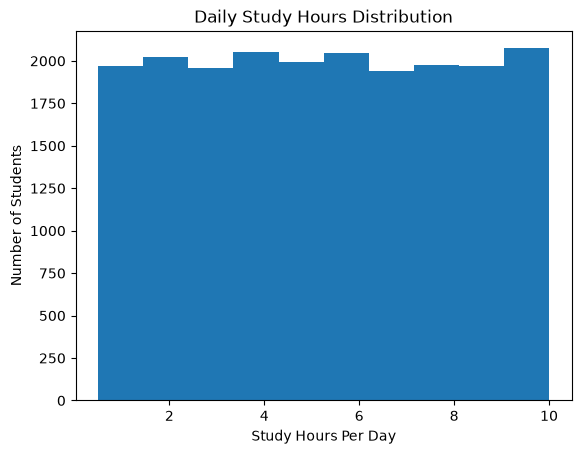

In [51]:
#Step 52 – Study Hours Distribution
plt.hist(df["study_hours_per_day"], bins=10)
plt.title("Daily Study Hours Distribution")
plt.xlabel("Study Hours Per Day")
plt.ylabel("Number of Students")
plt.show()


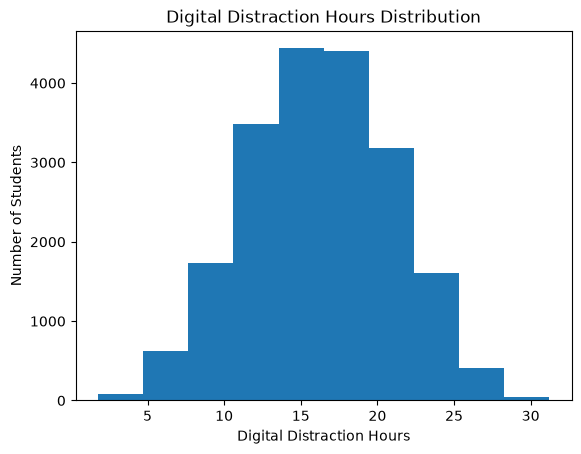

In [52]:
#Step 53 – Digital Distraction Distribution
plt.hist(df["digital_distraction_hours"], bins=10)
plt.title("Digital Distraction Hours Distribution")
plt.xlabel("Digital Distraction Hours")
plt.ylabel("Number of Students")
plt.show()


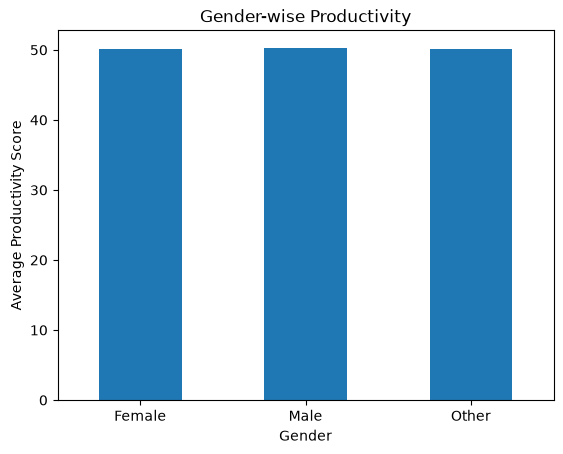

In [53]:
#Step 54 – Gender-wise Productivity
df.groupby("gender")["productivity_score"].mean().plot(kind="bar")
plt.title("Gender-wise Productivity")
plt.xlabel("Gender")
plt.ylabel("Average Productivity Score")
plt.xticks(rotation=0)
plt.show()


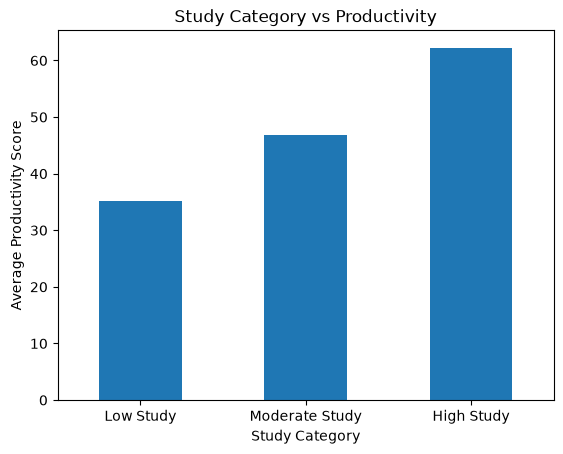

In [54]:
#Step 55 – Study Category vs Productivity
df.groupby("study_category", observed=True)["productivity_score"].mean().plot(kind="bar")
plt.title("Study Category vs Productivity")
plt.xlabel("Study Category")
plt.ylabel("Average Productivity Score")
plt.xticks(rotation=0)
plt.show()


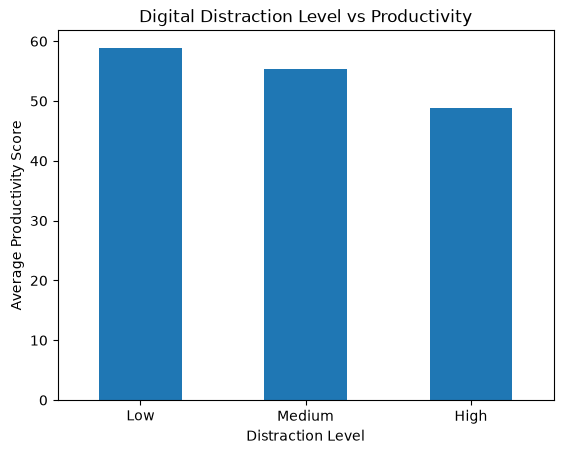

In [55]:
#Step 56 – Distraction Level vs Productivity
df.groupby("distraction_level", observed=True)["productivity_score"].mean().plot(kind="bar")
plt.title("Digital Distraction Level vs Productivity")
plt.xlabel("Distraction Level")
plt.ylabel("Average Productivity Score")
plt.xticks(rotation=0)
plt.show()


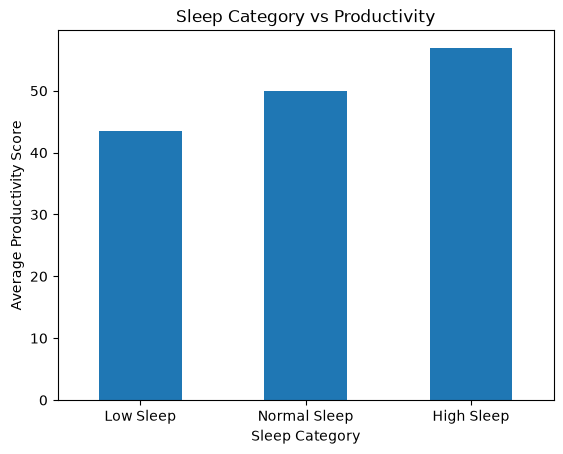

In [56]:
#Step 57 – Sleep Category vs Productivity
df.groupby("sleep_category", observed=True)["productivity_score"].mean().plot(kind="bar")
plt.title("Sleep Category vs Productivity")
plt.xlabel("Sleep Category")
plt.ylabel("Average Productivity Score")
plt.xticks(rotation=0)
plt.show()


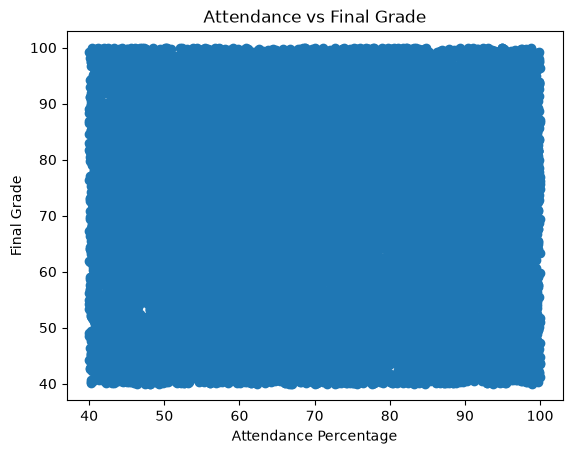

In [57]:
#Step 58 – Attendance vs Final Grade
plt.scatter(df["attendance_percentage"], df["final_grade"])
plt.title("Attendance vs Final Grade")
plt.xlabel("Attendance Percentage")
plt.ylabel("Final Grade")
plt.show()


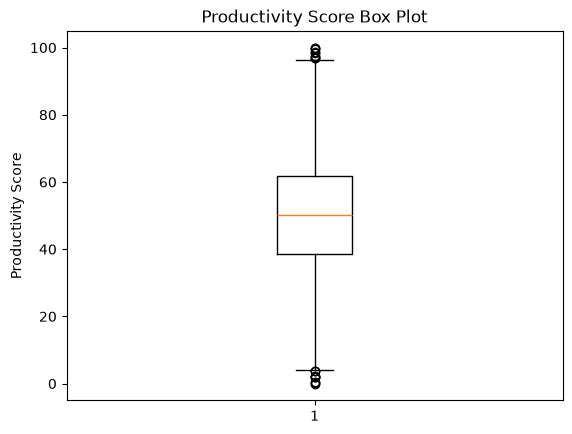

In [58]:
#Step 59 – Productivity Score Box Plot
plt.boxplot(df["productivity_score"])
plt.title("Productivity Score Box Plot")
plt.ylabel("Productivity Score")
plt.show()


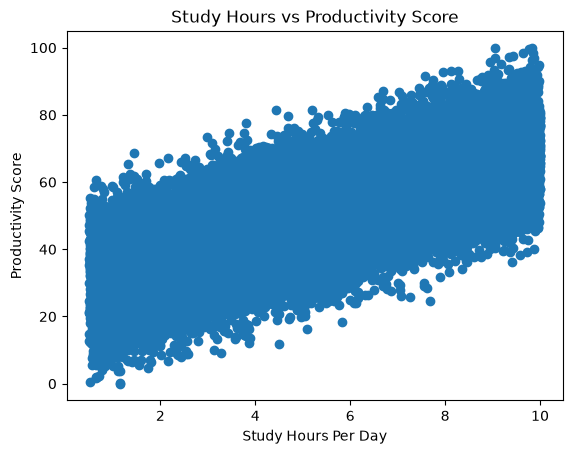

In [59]:
#Step 60 – Study Hours vs Productivity
plt.scatter(df["study_hours_per_day"], df["productivity_score"])
plt.title("Study Hours vs Productivity Score")
plt.xlabel("Study Hours Per Day")
plt.ylabel("Productivity Score")
plt.show()


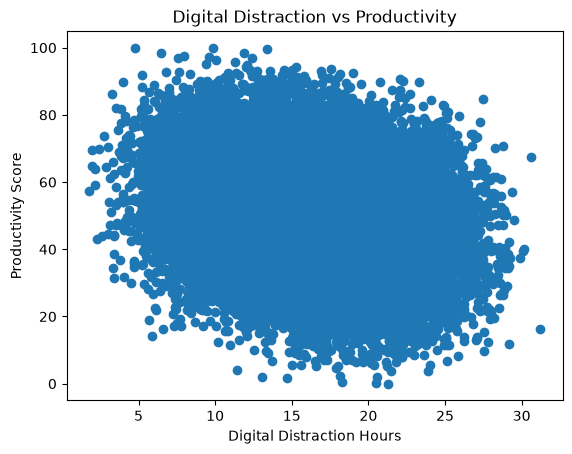

In [60]:
#Step 61 – Digital Distraction vs Productivity
plt.scatter(df["digital_distraction_hours"], df["productivity_score"])
plt.title("Digital Distraction vs Productivity")
plt.xlabel("Digital Distraction Hours")
plt.ylabel("Productivity Score")
plt.show()


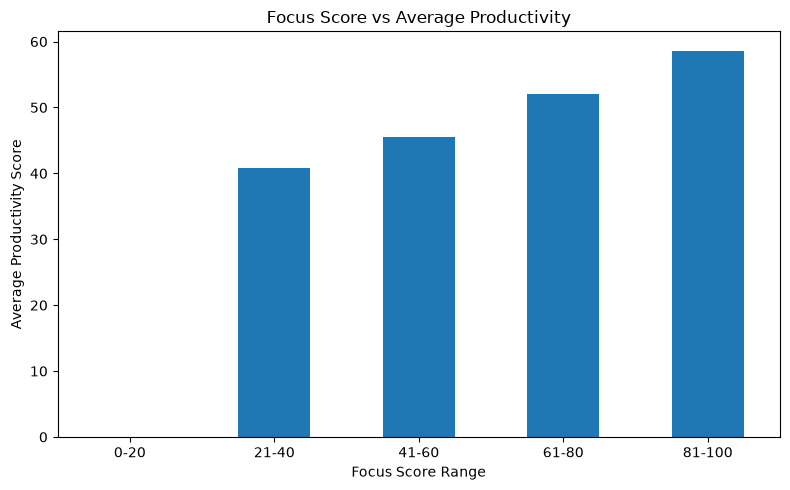

In [61]:
#Step 62 – Focus vs Productivity and Correlation Matrix
df["focus_category"] = pd.cut(
    df["focus_score"],
    bins=[0, 20, 40, 60, 80, 100],
    labels=["0-20", "21-40", "41-60", "61-80", "81-100"]
)

avg_productivity = df.groupby(
    "focus_category", observed=False
)["productivity_score"].mean()

avg_productivity.plot(kind="bar", figsize=(8, 5))

plt.title("Focus Score vs Average Productivity")
plt.xlabel("Focus Score Range")
plt.ylabel("Average Productivity Score")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [62]:
#Step 63 – Calculate Student Productivity Risk Score
df["Risk_Score"] = np.clip(
    0.35 * (100 - df["productivity_score"]) +
    0.25 * (100 - df["focus_score"]) +
    0.20 * (100 - df["attendance_percentage"]) +
    0.20 * np.clip(
        df["digital_distraction_hours"] / 24 * 100, 0, 100
    ),
    0, 100
)
print(df[["student_id", "Risk_Score"]].head())


   student_id  Risk_Score
0           1   53.485000
1           2   42.224500
2           3   56.187000
3           4   71.010167
4           5   55.229000


In [63]:
#Step 64 – Create Productivity Risk Category
df["Risk_Category"] = pd.cut(
    df["Risk_Score"],
    bins=[-np.inf, 30, 50, 70, np.inf],
    labels=["Low", "Medium", "High", "Critical"]
)
print(df["Risk_Category"].value_counts())


Risk_Category
Medium      11131
High         7002
Low          1646
Critical      221
Name: count, dtype: int64


In [64]:
#Step 65 – Create Productivity Eligibility Score
df["Eligibility_Score"] = np.clip(
    0.30 * df["productivity_score"] +
    0.25 * df["focus_score"] +
    0.20 * df["attendance_percentage"] +
    0.15 * np.clip(df["study_hours_per_day"] * 10, 0, 100) +
    0.10 * np.clip(100 - df["stress_level"] * 10, 0, 100),
    0, 100
)
print(df[["student_id", "Eligibility_Score"]].head())


   student_id  Eligibility_Score
0           1             42.351
1           2             54.411
2           3             48.578
3           4             35.348
4           5             50.731


In [65]:
#Step 66 – Identify High-Risk Students
high_risk = df[
    df["Risk_Category"].isin(["High", "Critical"])
]
print(high_risk[
    ["student_id", "productivity_score",
     "focus_score", "attendance_percentage",
     "Risk_Score", "Risk_Category"]
].head(15))
print("Count:", len(high_risk))


    student_id  productivity_score  focus_score  attendance_percentage  \
0            1               33.78           57                  57.21   
2            3               36.60           38                  63.14   
3            4               19.87           50                  40.51   
4            5               52.90           41                  45.53   
6            7               41.23           35                  43.50   
8            9               25.99           39                  44.79   
19          20               47.04           32                  40.50   
21          22               32.60           33                  98.42   
22          23               35.45           47                  94.13   
23          24               27.40           65                  44.19   
27          28               33.48           97                  43.56   
28          29               14.94           31                  59.49   
30          31               29.18    

In [66]:
#Step 67 – Calculate Productivity Probability
df["Productivity_Probability"] = (
    df["productivity_score"] / 100
)
print(df[
    ["student_id", "Productivity_Probability"]
].head())


   student_id  Productivity_Probability
0           1                    0.3378
1           2                    0.4899
2           3                    0.3660
3           4                    0.1987
4           5                    0.5290


In [67]:
#Step 68 – Create Smart Recommendation Function
import pandas as pd
df["digital_distraction_hours"] = (
    df["phone_usage_hours"]
    + df["social_media_hours"]
    + df["youtube_hours"]
    + df["gaming_hours"]
)
def smart_recommendation(row):
    tips = []
    if row["digital_distraction_hours"] > 12:
        tips.append("Reduce unnecessary digital screen time")

    if row["study_hours_per_day"] < 4:
        tips.append("Increase focused study time")

    if row["sleep_hours"] < 6:
        tips.append("Improve sleep routine")

    if row["focus_score"] < 50:
        tips.append("Use distraction-free study sessions")

    if row["attendance_percentage"] < 75:
        tips.append("Improve class attendance")

    if row["exercise_minutes"] < 30:
        tips.append("Add regular physical activity")

    if row["assignments_completed"] < 5:
        tips.append("Complete more assignments")

    if not tips:
        tips.append("Maintain the current routine")

    return "; ".join(tips)
df["assistant_recommendation"] = df.apply(
    smart_recommendation,
    axis=1
)
print(df[[
    "student_id",
    "digital_distraction_hours",
    "assistant_recommendation"
]].head(10))

   student_id  digital_distraction_hours  \
0           1                      13.20   
1           2                      11.85   
2           3                      13.35   
3           4                      22.28   
4           5                      15.72   
5           6                       9.34   
6           7                      24.08   
7           8                      14.17   
8           9                      16.01   
9          10                       6.84   

                            assistant_recommendation  
0  Reduce unnecessary digital screen time; Improv...  
1  Use distraction-free study sessions; Add regul...  
2  Reduce unnecessary digital screen time; Improv...  
3  Reduce unnecessary digital screen time; Increa...  
4  Reduce unnecessary digital screen time; Use di...  
5  Improve sleep routine; Improve class attendanc...  
6  Reduce unnecessary digital screen time; Use di...  
7  Reduce unnecessary digital screen time; Improv...  
8  Reduce unnecessar

In [68]:
#Step 69 – Create Productivity Prediction Target
df["high_productivity"] = (
    df["productivity_score"] >= 70
).astype(int)
print(df["high_productivity"].value_counts())


high_productivity
0    17679
1     2321
Name: count, dtype: int64


In [69]:
#Step 70 – Select Machine-Learning Features
features = [
    "age", "gender", "study_hours_per_day",
    "sleep_hours", "phone_usage_hours",
    "social_media_hours", "youtube_hours",
    "gaming_hours", "breaks_per_day",
    "coffee_intake_mg", "exercise_minutes",
    "assignments_completed", "attendance_percentage",
    "stress_level", "focus_score", "final_grade"
]

X = pd.get_dummies(
    df[features],
    columns=["gender"],
    dtype=int
)
y = df["high_productivity"]

print("X shape:", X.shape)
print("y shape:", y.shape)


X shape: (20000, 18)
y shape: (20000,)


In [70]:
#Step 71 – Split Data for AI Model
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)
print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))


Training rows: 16000
Testing rows: 4000


In [71]:
#Step 72 – Train Random Forest Classifier
model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)
model.fit(X_train, y_train)
print("Random Forest model trained successfully.")


Random Forest model trained successfully.


In [72]:
#Step 73 – Predict Test Data and Calculate Accuracy
y_pred = model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy)


Accuracy: 0.962


              precision    recall  f1-score   support

           0       0.96      1.00      0.98      3536
           1       0.97      0.69      0.81       464

    accuracy                           0.96      4000
   macro avg       0.97      0.85      0.89      4000
weighted avg       0.96      0.96      0.96      4000

Confusion Matrix:
[[3526   10]
 [ 142  322]]
study_hours_per_day      0.318934
focus_score              0.151121
sleep_hours              0.112048
phone_usage_hours        0.105669
attendance_percentage    0.056219
stress_level             0.035792
gaming_hours             0.027552
final_grade              0.027521
youtube_hours            0.027149
social_media_hours       0.026677
dtype: float64


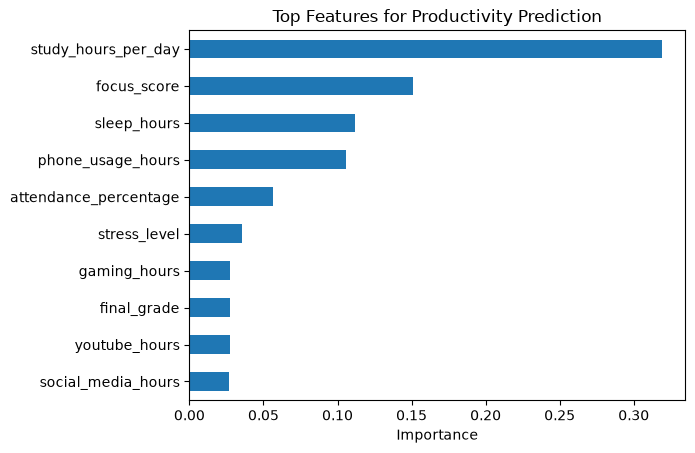

In [73]:
#Step 74 – Generate Classification Report, Confusion Matrix and Feature Importance
print(classification_report(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:")
print(cm)

importance = pd.Series(
    model.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

print(importance.head(10))

importance.head(10).sort_values().plot(kind="barh")
plt.title("Top Features for Productivity Prediction")
plt.xlabel("Importance")
plt.show()


In [74]:
#Step 75 – Predict a New Student and Generate Final Smart Assistant Output
new_student = pd.DataFrame([{
    "age": 20,
    "gender": "Male",
    "study_hours_per_day": 6,
    "sleep_hours": 7,
    "phone_usage_hours": 3,
    "social_media_hours": 1,
    "youtube_hours": 1,
    "gaming_hours": 1,
    "breaks_per_day": 5,
    "coffee_intake_mg": 150,
    "exercise_minutes": 45,
    "assignments_completed": 10,
    "attendance_percentage": 85,
    "stress_level": 4,
    "focus_score": 80,
    "final_grade": 82
}])

new_student["digital_distraction_hours"] = (
    new_student["phone_usage_hours"]
    + new_student["social_media_hours"]
    + new_student["youtube_hours"]
    + new_student["gaming_hours"]
)

new_student = pd.get_dummies(
    new_student,
    columns=["gender"],
    dtype=int
)

new_student = new_student.reindex(
    columns=X.columns,
    fill_value=0
)

prediction = model.predict(new_student)[0]
probability = model.predict_proba(new_student)[0, 1]

print("Predicted productivity class:",
      "High" if prediction == 1 else "Not High")

print("Productivity probability:",
      round(probability, 2))

Predicted productivity class: Not High
Productivity probability: 0.16


In [77]:
# Step 76 – Optimize Random Forest Model 
from sklearn.model_selection import GridSearchCV
param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [None, 10, 20],
    "min_samples_split": [2, 5]
}
grid_search = GridSearchCV(
    RandomForestClassifier(random_state=42),
    param_grid,
    cv=3,
    scoring="accuracy",
    n_jobs=-1
)
grid_search.fit(X_train, y_train)
print("Best Parameters:")
print(grid_search.best_params_)

Best Parameters:
{'max_depth': None, 'min_samples_split': 2, 'n_estimators': 200}


In [78]:
#Step 77 – Select Optimized Model
optimized_model = grid_search.best_estimator_
print("Optimized Random Forest model selected successfully.")

Optimized Random Forest model selected successfully.


In [79]:
#Step 78 – Predict Using Optimized Model
optimized_y_pred = optimized_model.predict(X_test)
print("Optimized predictions generated successfully.")

Optimized predictions generated successfully.


In [80]:
#Step 79 – Calculate Optimized Accuracy
optimized_accuracy = accuracy_score(
    y_test,
    optimized_y_pred
)
print(
    "Optimized Model Accuracy:",
    round(optimized_accuracy * 100, 2),
    "%"
)

Optimized Model Accuracy: 96.23 %


In [81]:
#Step 80 – Compare Original and Optimized Models
print("Original Model Accuracy:",
      round(accuracy * 100, 2), "%")
print("Optimized Model Accuracy:",
      round(optimized_accuracy * 100, 2), "%")
print(
    "Accuracy Improvement:",
    round((optimized_accuracy - accuracy) * 100, 2),
    "%"
)

Original Model Accuracy: 96.2 %
Optimized Model Accuracy: 96.23 %
Accuracy Improvement: 0.03 %


In [82]:
#Step 81 – Generate Optimized Classification Report
print("Optimized Classification Report:")
print(
    classification_report(
        y_test,
        optimized_y_pred
    )
)

Optimized Classification Report:
              precision    recall  f1-score   support

           0       0.96      1.00      0.98      3536
           1       0.97      0.70      0.81       464

    accuracy                           0.96      4000
   macro avg       0.97      0.85      0.89      4000
weighted avg       0.96      0.96      0.96      4000



In [83]:
#Step 82 – Generate Optimized Confusion Matrix
optimized_cm = confusion_matrix(
    y_test,
    optimized_y_pred
)

print("Optimized Confusion Matrix:")
print(optimized_cm)

Optimized Confusion Matrix:
[[3526   10]
 [ 141  323]]


In [84]:
#Step 83 – Analyze Optimized Feature Importance
optimized_importance = pd.Series(
    optimized_model.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

print("Top Important Features:")
print(optimized_importance.head(10))

Top Important Features:
study_hours_per_day      0.318653
focus_score              0.151473
sleep_hours              0.114232
phone_usage_hours        0.105659
attendance_percentage    0.056526
stress_level             0.035523
final_grade              0.027168
gaming_hours             0.026879
youtube_hours            0.026789
social_media_hours       0.026255
dtype: float64


In [85]:
#Step 84 – Generate Final Productivity Predictions
df["final_productivity_prediction"] = optimized_model.predict(X)

df["final_productivity_probability"] = (
    optimized_model.predict_proba(X)[:, 1]
)

print(
    df[
        [
            "student_id",
            "final_productivity_prediction",
            "final_productivity_probability"
        ]
    ].head(10)
)

   student_id  final_productivity_prediction  final_productivity_probability
0           1                              0                           0.000
1           2                              0                           0.005
2           3                              0                           0.000
3           4                              0                           0.000
4           5                              0                           0.000
5           6                              0                           0.000
6           7                              0                           0.015
7           8                              0                           0.020
8           9                              0                           0.000
9          10                              1                           0.830


In [86]:
#Step 85 – Display Final Project Results
print("========== FINAL PROJECT RESULTS ==========")
print(
    "Original Model Accuracy:",
    round(accuracy * 100, 2),
    "%"
)
print(
    "Optimized Model Accuracy:",
    round(optimized_accuracy * 100, 2),
    "%"
)
print(
    "Best Parameters:",
    grid_search.best_params_
)
print(
    "Number of Students:",
    len(df)
)
print(
    "Average Productivity Score:",
    round(df["productivity_score"].mean(), 2)
)
print(
    "Average Digital Distraction:",
    round(df["digital_distraction_hours"].mean(), 2)
)
print("===========================================")

========== FINAL PROJECT RESULTS ==========
Original Model Accuracy: 96.2 %
Optimized Model Accuracy: 96.23 %
Best Parameters: {'max_depth': None, 'min_samples_split': 2, 'n_estimators': 200}
Number of Students: 20000
Average Productivity Score: 50.18
Average Digital Distraction: 16.23
